# 2026/10/22：capsule画像の回転拡張と切り取りの影響の検証

## 今回の問い：丸くない対象にも回転拡張は使えるか？
横長のカプセル画像で、回転後の形・向き・印字と、画像の端で失われる部分を確認します。
**画像加工の検証です。学習・モデル推論・AUROC評価は行いません。**

調べる影響を二つに分けます。
1. **切り出しの影響**：1000×1000から中央820×820だけを残す時点で、被写体の端が欠けないか。
2. **回転の影響**：画像の枠を維持すると、外へ出る部分の切り捨てと白埋めがどう生じるか。

| 方法 | 回転前の画像 | 回転後の枠 | 最終画像 |
|---|---|---|---|
| ① 中央切り出し・枠維持 | 中央820×820 | 820×820 | 128×128 |
| ② 全体・枠維持 | 元の1000×1000全体 | 1000×1000 | 128×128 |
| ③ 全体・枠拡大 | 元の1000×1000全体 | 角度に合わせ拡大 | 128×128 |

①は現在のボトル用前処理に対応します。**capsuleでは②「元画像1000×1000全体・回転後も枠維持」を採用します（ユーザー決定）。** ①③は比較用に残します。性能の優劣は未検証です。

採用方法の最終10画像は「5-2」に白黒・カラーで表示します。第3・4節の中央820×820を用いた図は、比較のための従来例です。
元データは変更せず、画像はメモリ内で生成します。上から実行し、設定セルの画像名を変えると別画像で確認できます。

In [1]:
from pathlib import Path
from io import BytesIO
import hashlib, json, importlib.metadata
import numpy as np
import pandas as pd
from PIL import Image
from torchvision import transforms
import torchvision.transforms.functional as TF
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.patches import Rectangle
from IPython.display import display
%matplotlib inline
ROOT=next((p for p in (Path.cwd(),*Path.cwd().parents) if (p/'data/capsule/train/good').is_dir()),None)
if ROOT is None: raise FileNotFoundError('リポジトリ内で実行してください。')
TRAIN_DIR=ROOT/'data/capsule/train/good'
IMAGE_NAME=None  # None：先頭画像。例 '015.png' に変更できる。
ANGLES=tuple(range(0,360,36))
COMPARE_ANGLES=(36,72,144)
CROP_SIZE=820
OUTPUT_SIZE=128
FILL_VALUE=255
paths=sorted(TRAIN_DIR.glob('*.png'),key=lambda p:p.name)
if not paths: raise FileNotFoundError(TRAIN_DIR)
image_path=paths[0] if IMAGE_NAME is None else TRAIN_DIR/IMAGE_NAME
if not image_path.is_file(): raise FileNotFoundError(image_path)
if not set(COMPARE_ANGLES)<=set(ANGLES): raise ValueError('比較角度はANGLESから選んでください。')
source_hashes={p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in paths}
fonts={f.name for f in font_manager.fontManager.ttflist}
for name in ['Yu Gothic','Meiryo','MS Gothic','Noto Sans CJK JP','IPAexGothic']:
    if name in fonts:
        plt.rcParams['font.family']=name
        break
else:
    import japanize_matplotlib
plt.rcParams.update({'font.size':11,'axes.unicode_minus':False,'figure.dpi':100})
crop=transforms.CenterCrop(CROP_SIZE)
resize=transforms.Resize((OUTPUT_SIZE,OUTPUT_SIZE),interpolation=transforms.InterpolationMode.LANCZOS)
gray=transforms.Grayscale(num_output_channels=1)
to_tensor=transforms.ToTensor()
def read_rgb(path):
    with Image.open(BytesIO(path.read_bytes())) as im: return im.convert('RGB').copy()
def rotate(im,angle,expand=False,fill=FILL_VALUE):
    return im.copy() if angle==0 else TF.rotate(im,angle,interpolation=transforms.InterpolationMode.NEAREST,expand=expand,fill=fill)
def finish(im): return gray(resize(im))
def show(ax,im,title):
    a=np.asarray(im)
    if a.ndim==2: ax.imshow(a,cmap='gray',vmin=0,vmax=255,interpolation='nearest')
    else: ax.imshow(a,interpolation='nearest')
    ax.set_title(title,fontsize=11); ax.axis('off')
original=read_rgb(image_path)
if min(original.size)<CROP_SIZE: raise ValueError('820より小さい画像は今回は対象外です。')
cropped=crop(original)
print(f'確認画像：{image_path.relative_to(ROOT)} / 元画像：{original.size}')
print(f'訓練正常画像：{len(paths)}枚 → 反復・回転とも延べ{len(paths)*len(ANGLES):,}サンプル')
print('学習・モデル推論は実行しません。')

確認画像：data\capsule\train\good\000.png / 元画像：(1000, 1000)
訓練正常画像：219枚 → 反復・回転とも延べ2,190サンプル
学習・モデル推論は実行しません。


## 1. 複数の正常画像を見て、向き・配置を確認する
先頭・約1/5間隔・末尾から6枚を表示します。正常画像の向きや配置の例であり、これだけでデータ全体の向きの分布を測ったことにはなりません。
回転した向きが実際の撮影で生じるか、印字の向きが検査上重要かも考えてください。

,画像サイズ,枚数
0,"(1000, 1000)",219


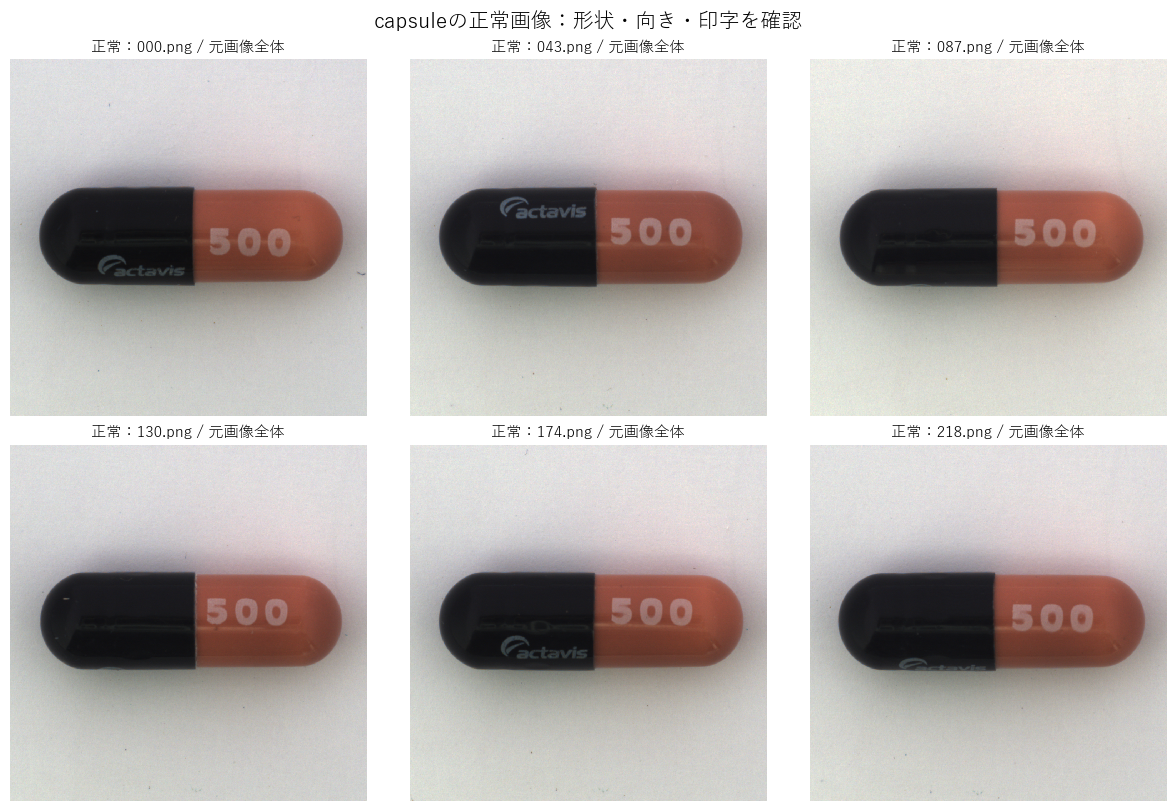

In [2]:
sizes={p.name:read_rgb(p).size for p in paths}
display(pd.Series(list(sizes.values()),dtype=object).value_counts().rename_axis('画像サイズ').reset_index(name='枚数'))
gallery_indices=np.unique(np.linspace(0,len(paths)-1,min(6,len(paths)),dtype=int))
fig,axes=plt.subplots(2,3,figsize=(12,8),constrained_layout=True)
for ax in axes.flat: ax.axis('off')
for ax,idx in zip(axes.flat,gallery_indices): show(ax,read_rgb(paths[idx]),f'正常：{paths[idx].name} / 元画像全体')
fig.suptitle('capsuleの正常画像：形状・向き・印字を確認',fontsize=15)
plt.show(); plt.close(fig)

## 2. 回転の前に、中央切り出しの影響を確認する
1000×1000の中央820×820を残す場合、上下左右を90画素ずつ除きます。先頭画像ではカプセルの両端の一部もこの範囲外になります。
**回転による欠けとは区別してください。** 赤枠が残す領域です。画像全体を直接128×128に縮小する例も並べます。

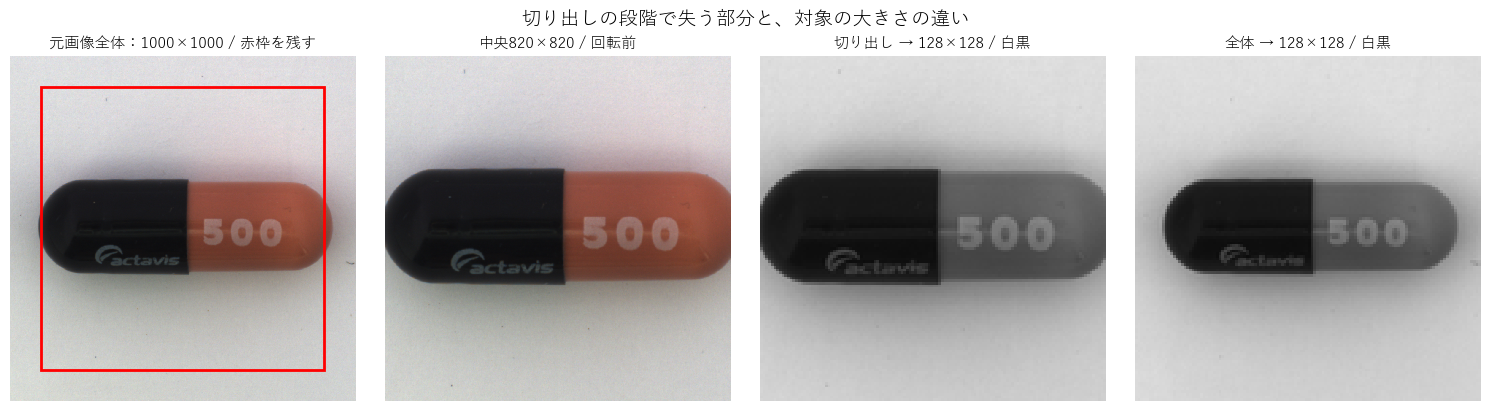

中央切り出しで除く面積：32.76%（元画像の矩形面積に対する割合）
この割合はカプセル自体の欠損率ではありません。被写体の切れは画像を見て確認します。


In [3]:
w,h=original.size
x0=int(round((w-CROP_SIZE)/2)); y0=int(round((h-CROP_SIZE)/2))
fig,axes=plt.subplots(1,4,figsize=(15,4),constrained_layout=True)
show(axes[0],original,f'元画像全体：{w}×{h} / 赤枠を残す')
axes[0].add_patch(Rectangle((x0-.5,y0-.5),CROP_SIZE,CROP_SIZE,fill=False,edgecolor='red',linewidth=2))
show(axes[1],cropped,'中央820×820 / 回転前')
show(axes[2],finish(cropped),'切り出し → 128×128 / 白黒')
show(axes[3],finish(original),'全体 → 128×128 / 白黒')
fig.suptitle('切り出しの段階で失う部分と、対象の大きさの違い',fontsize=14)
plt.show(); plt.close(fig)
print(f'中央切り出しで除く面積：{100*(1-CROP_SIZE**2/(w*h)):.2f}%（元画像の矩形面積に対する割合）')
print('この割合はカプセル自体の欠損率ではありません。被写体の切れは画像を見て確認します。')

## 3. 反復拡張：同じ画像を10回使う
比較の基準は①の中央切り出しです。**画素値は変わりません。** 10個の画像ファイルを作らず、同じ128×128画像を繰り返し参照します。
219枚×10回＝延べ2,190サンプルですが、独立した新しい元画像が増えたわけではありません。

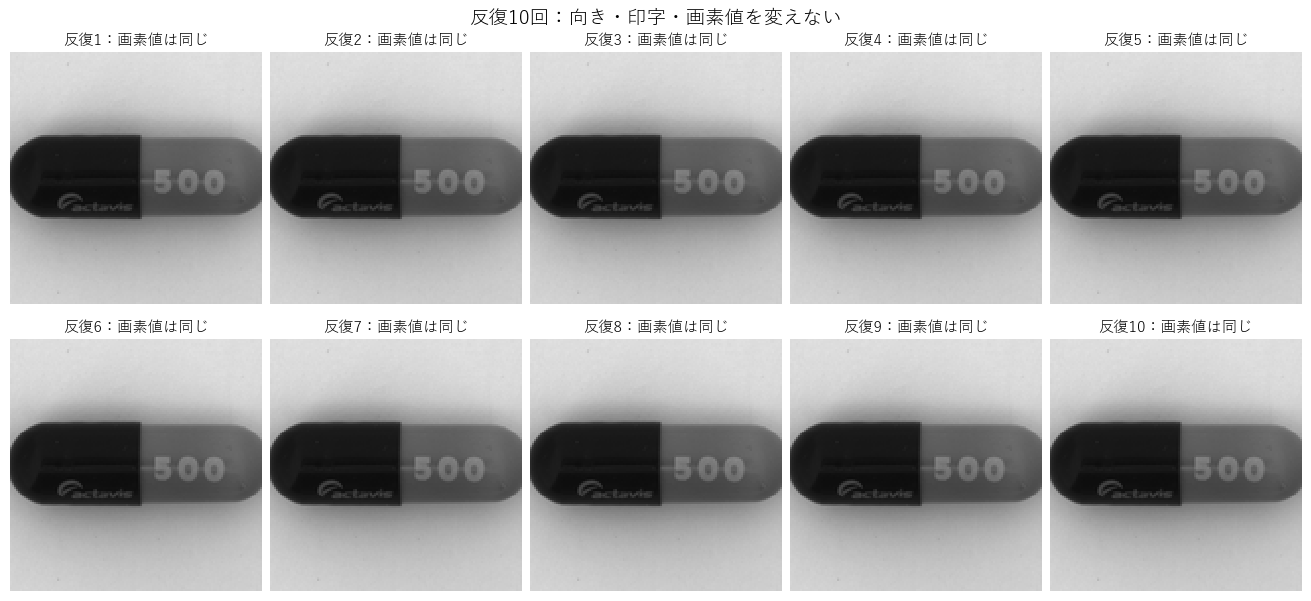

10枚すべての画素値が完全一致：True


In [4]:
base=finish(cropped)
repeats=[base for _ in ANGLES]
assert all(np.array_equal(np.asarray(im),np.asarray(base)) for im in repeats)
fig,axes=plt.subplots(2,5,figsize=(13,6),constrained_layout=True)
for i,(ax,im) in enumerate(zip(axes.flat,repeats),1): show(ax,im,f'反復{i}：画素値は同じ')
fig.suptitle('反復10回：向き・印字・画素値を変えない',fontsize=14)
plt.show(); plt.close(fig)
print('10枚すべての画素値が完全一致：True')

## 4. 回転拡張：高解像度で回転してから128×128へ縮小する
①中央820×820に対して0〜324度の36度刻み、計10方向を作ります。毎回同じ切り出し画像から直接回転し、回転を重ねません。
回転はNEAREST（最近傍補間）、fill=255（白埋め）、expand=False（枠維持）。最後はLANCZOS縮小→白黒→0〜1の数値です。
カラー図は向き・印字を見やすくする説明用です。今回想定するモデル入力は白黒128×128、形(1,128,128)のfloat32です。

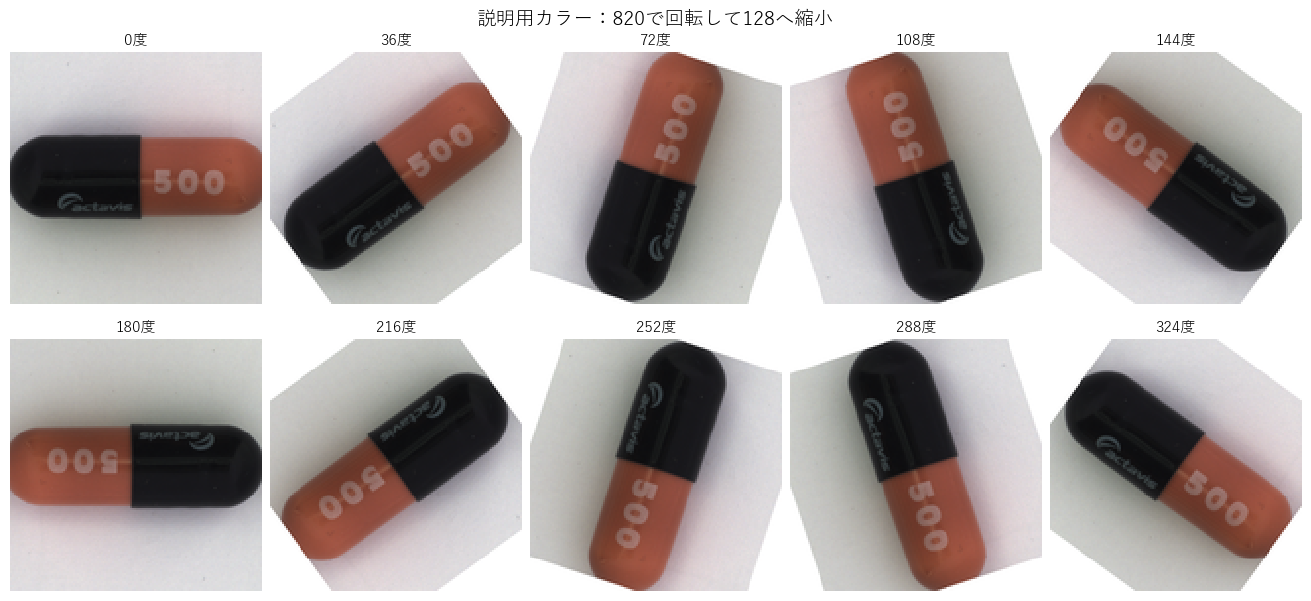

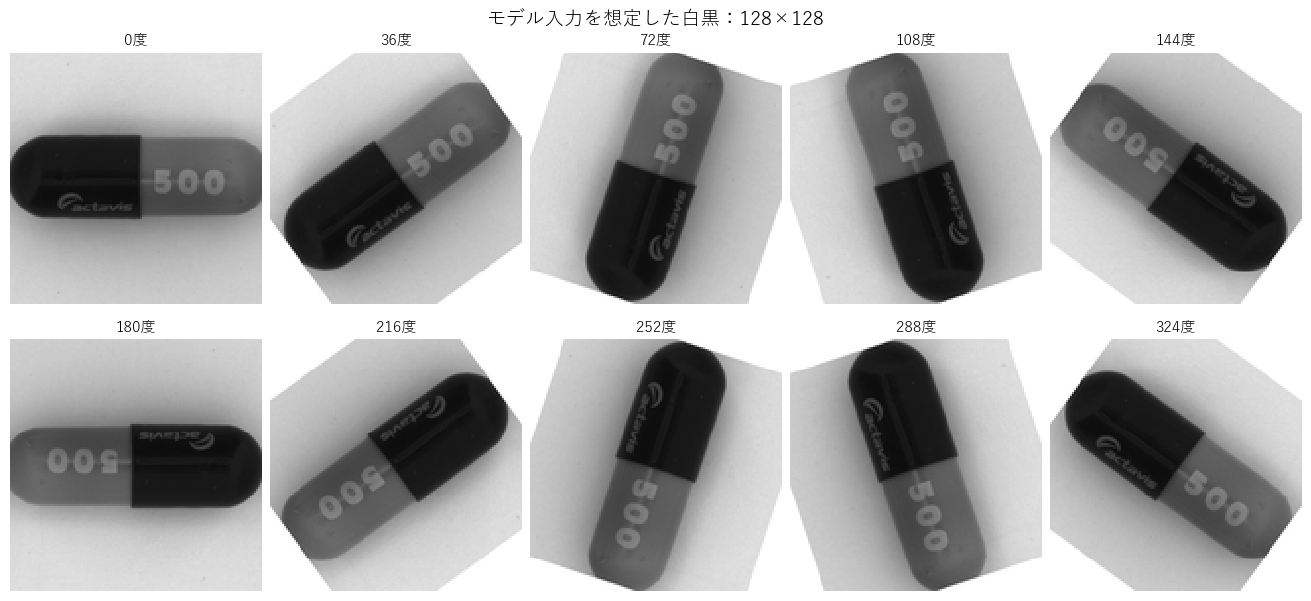

0度と反復画像が一致：True / モデル入力の範囲：0〜1


In [5]:
rotated_crop={a:rotate(cropped,a) for a in ANGLES}
rotated_gray={a:finish(im) for a,im in rotated_crop.items()}
for label,images in [('説明用カラー：820で回転して128へ縮小',{a:resize(im) for a,im in rotated_crop.items()}),('モデル入力を想定した白黒：128×128',rotated_gray)]:
    fig,axes=plt.subplots(2,5,figsize=(13,6),constrained_layout=True)
    for ax,a in zip(axes.flat,ANGLES): show(ax,images[a],f'{a}度')
    fig.suptitle(label,fontsize=14)
    plt.show(); plt.close(fig)
assert np.array_equal(np.asarray(rotated_gray[0]),np.asarray(base))
inputs={a:to_tensor(im) for a,im in rotated_gray.items()}
assert all(tuple(t.shape)==(1,128,128) and 0<=float(t.min())<=float(t.max())<=1 for t in inputs.values())
print('0度と反復画像が一致：True / モデル入力の範囲：0〜1')

## 5. 切り出し・枠維持・枠拡大を、同じ角度で比較する
①②は元の四角い枠から外へ出た部分を失います。③は回転した画像全体が入る枠に拡大します。
**③を128×128に縮小すると、枠が広い分だけ対象が小さくなります。** ①の切り出しも対象を相対的に大きくするため、3方法の最終的な対象サイズは揃いません。
白埋めは元の背景を保護する指定ではなく、参照元のない画素を純白255にする処理です。実背景と明るさ・模様が異なることも確認します。

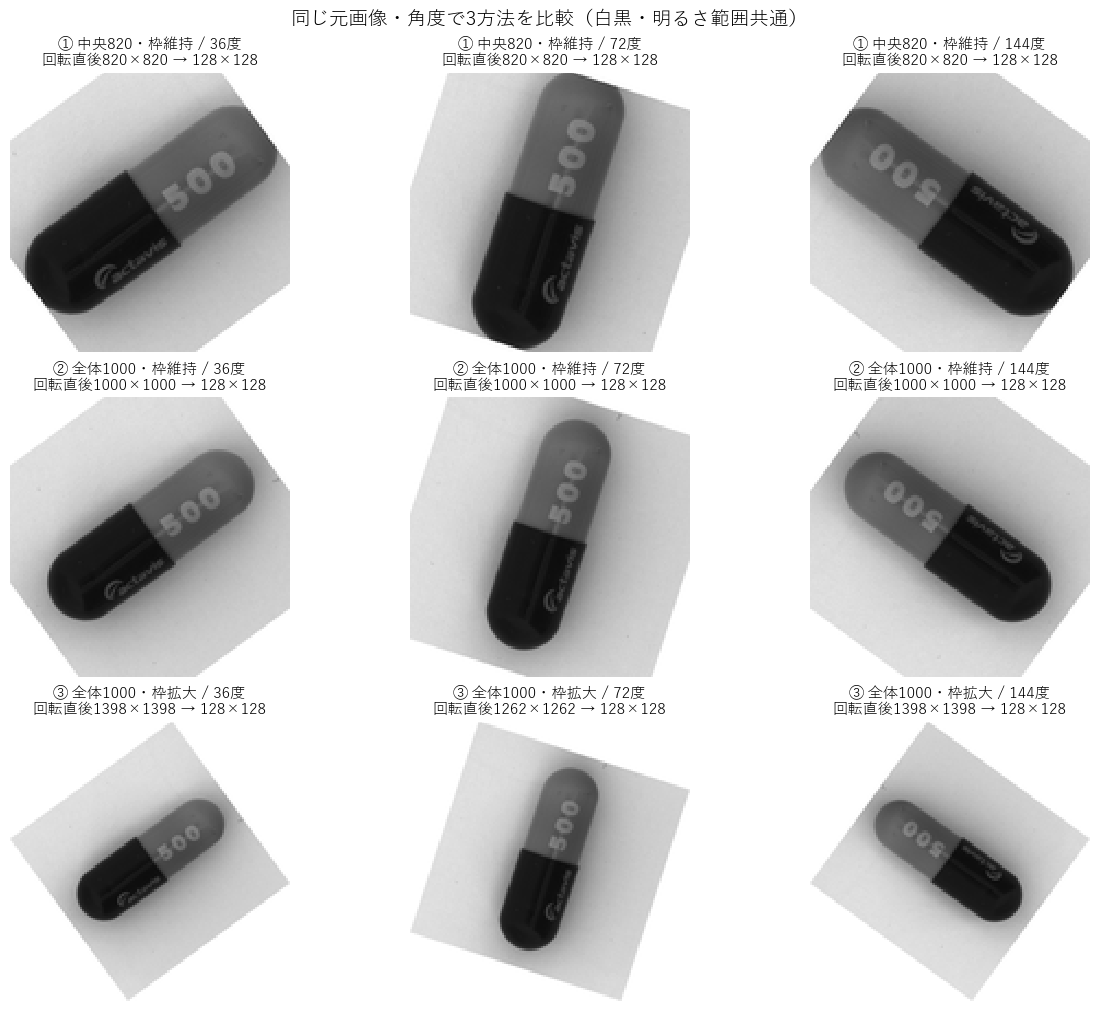

In [6]:
METHODS={'crop_fixed':('① 中央820・枠維持',cropped,False),'full_fixed':('② 全体1000・枠維持',original,False),'full_expand':('③ 全体1000・枠拡大',original,True)}
variants={key:{a:rotate(im,a,expand=expand) for a in ANGLES} for key,(_,im,expand) in METHODS.items()}
fig,axes=plt.subplots(3,len(COMPARE_ANGLES),figsize=(12,10),squeeze=False,constrained_layout=True)
for row,(key,(label,im,expand)) in enumerate(METHODS.items()):
    for col,a in enumerate(COMPARE_ANGLES):
        out=variants[key][a]
        show(axes[row,col],finish(out),f'{label} / {a}度\n回転直後{out.size[0]}×{out.size[1]} → 128×128')
fig.suptitle('同じ元画像・角度で3方法を比較（白黒・明るさ範囲共通）',fontsize=14)
plt.show(); plt.close(fig)

## 5-2. 採用する②の方法：1枚から作る最終10画像

**元画像1000×1000全体 → その解像度で回転（枠維持・白埋め）→ LANCZOSで128×128へ縮小 → グレースケール化 → 0〜1の数値**、を採用します。中央820×820への切り出しは行いません。

0・36・72・108・144・180・216・252・288・324度の計10枚です。0度は回転を省略した元の向きで、追加の10方向と合わせて11枚という意味ではありません。各角度は同じ元画像から直接作ります。

最初の白黒一覧が最終入力を想定した画像です。下のカラー一覧は向きや印字を確認するための説明用です。両方とも実際の画像データは128×128で、画面上は見やすく拡大しています。回転時の枠は1000×1000を維持するため、画像領域の一部の切り捨てと白埋めは生じ得ます。

先頭の設定セルで `IMAGE_NAME` を変え、上から再実行すると別の画像も確認できます。

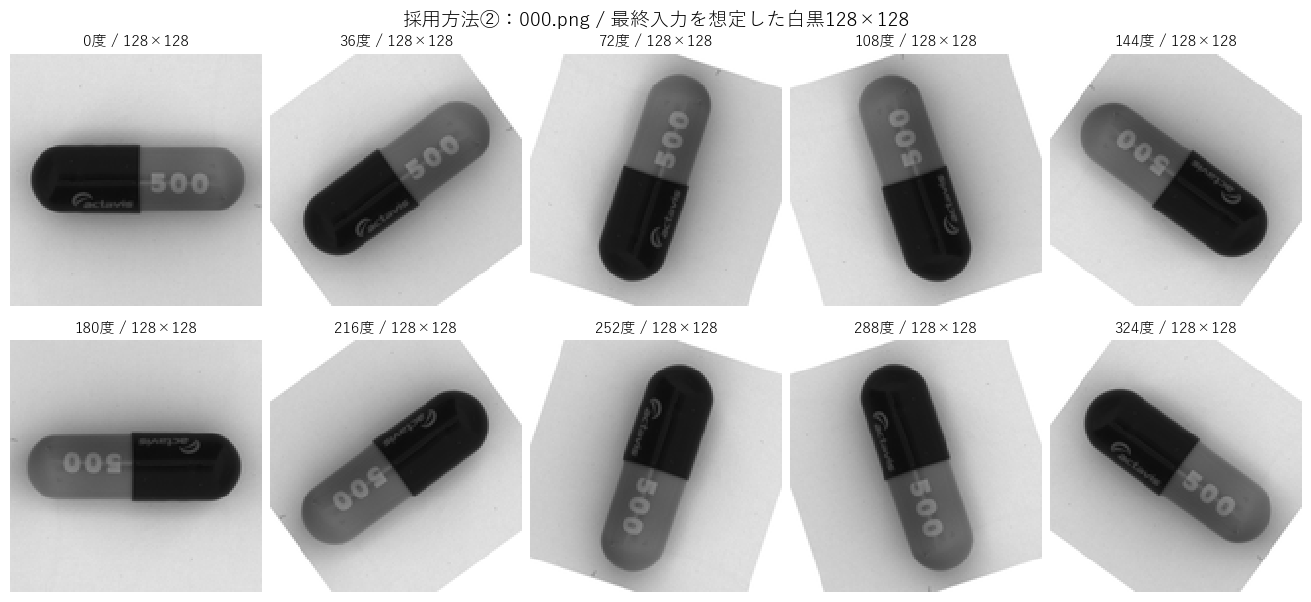

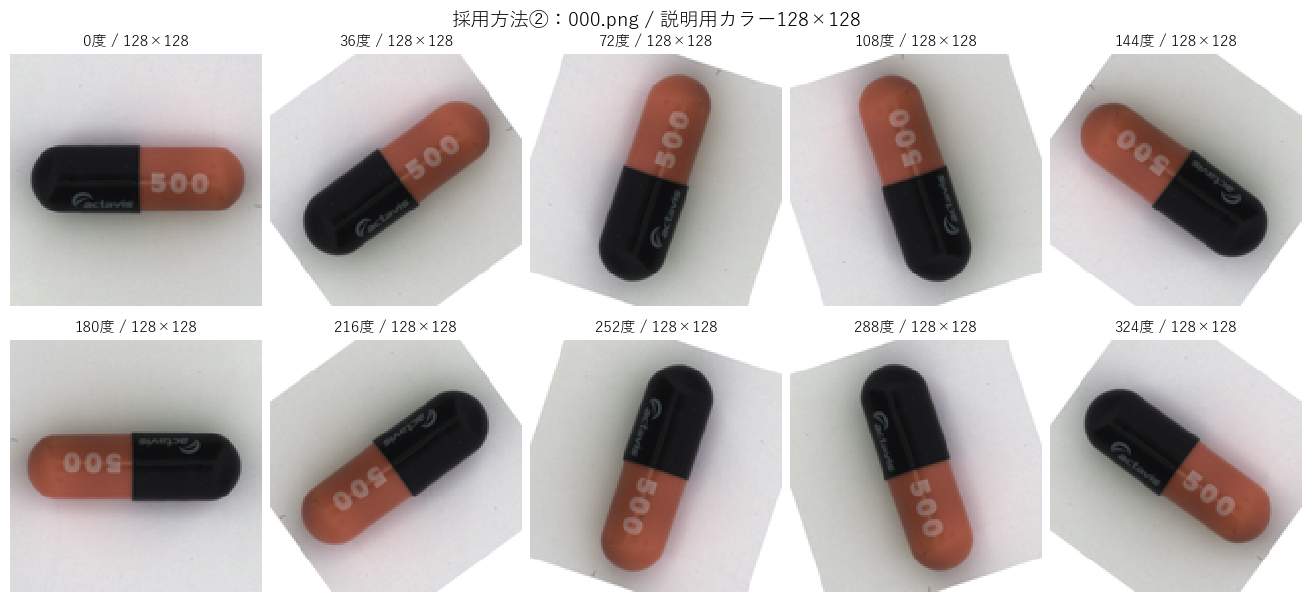

採用方法：② 元画像全体・枠維持 / 0度を含めて10枚
回転直後のサイズ： (1000, 1000)  / 最終入力：(1,128,128)、float32、0〜1


In [7]:
ADOPTED_METHOD='full_fixed'
adopted_highres=variants[ADOPTED_METHOD]
adopted_color={a:resize(adopted_highres[a]) for a in ANGLES}
adopted_gray={a:gray(adopted_color[a]) for a in ANGLES}
adopted_inputs={a:to_tensor(adopted_gray[a]) for a in ANGLES}
assert len(adopted_inputs)==10
assert all(im.size==original.size for im in adopted_highres.values())
assert all(im.size==(128,128) for im in adopted_color.values())
assert all(im.size==(128,128) for im in adopted_gray.values())
assert np.array_equal(np.asarray(adopted_gray[0]),np.asarray(finish(original)))
for a,t in adopted_inputs.items():
    assert tuple(t.shape)==(1,128,128) and 0<=float(t.min())<=float(t.max())<=1
    assert np.allclose(t.numpy()[0],np.asarray(adopted_gray[a],dtype=np.float32)/255)
for title,images in [('最終入力を想定した白黒128×128',adopted_gray),('説明用カラー128×128',adopted_color)]:
    fig,axes=plt.subplots(2,5,figsize=(13,6),constrained_layout=True)
    for ax,a in zip(axes.flat,ANGLES): show(ax,images[a],f'{a}度 / 128×128')
    fig.suptitle(f'採用方法②：{image_path.name} / {title}',fontsize=14)
    plt.show(); plt.close(fig)
print('採用方法：② 元画像全体・枠維持 / 0度を含めて10枚')
print('回転直後のサイズ：',original.size,' / 最終入力：(1,128,128)、float32、0〜1')


## 6. マスクで、画像領域の切り捨てと白埋めを測る
被写体を自動抽出するのではなく、**画像の四角形全体**を白255にした説明用マスクを回転します。回転のfillは黒0です。図の白が元画像由来、黒が白埋め対象に対応します。正解の異常マスクではありません。

- **白埋め率**＝回転後の枠内で元画像を参照できない画素の割合。縮小前のマスクで数えます。
- **回転による切り捨て率（概算）**＝同じ画像・角度を枠拡大で回転した場合の白画素数と比べ、枠維持で失った白画素数の割合。画素格子上の近似で、物体面積の計測ではありません。
- ①の切り捨て率は**中央切り出し後の820×820**が基準です。前段の切り出しによる損失は含みません。

マスクを図示する際の縮小も最近傍にして、白黒の意味を保ちます。この数値は被写体の欠損率・画質・異常検知性能ではありません。

,方法,角度,回転後の幅,回転後の高さ,白埋め率(%),回転による切り捨て率・概算(%)
0,① 中央820・枠維持,0,820,820,0.000,0.000
1,① 中央820・枠維持,36,820,820,16.556,16.555
2,① 中央820・枠維持,72,820,820,11.507,11.507
3,① 中央820・枠維持,108,820,820,11.507,11.507
4,① 中央820・枠維持,144,820,820,16.556,16.555
5,① 中央820・枠維持,180,820,820,0.000,0.000
6,① 中央820・枠維持,216,820,820,16.556,16.555
7,① 中央820・枠維持,252,820,820,11.507,11.507
8,① 中央820・枠維持,288,820,820,11.507,11.507
9,① 中央820・枠維持,324,820,820,16.556,16.555


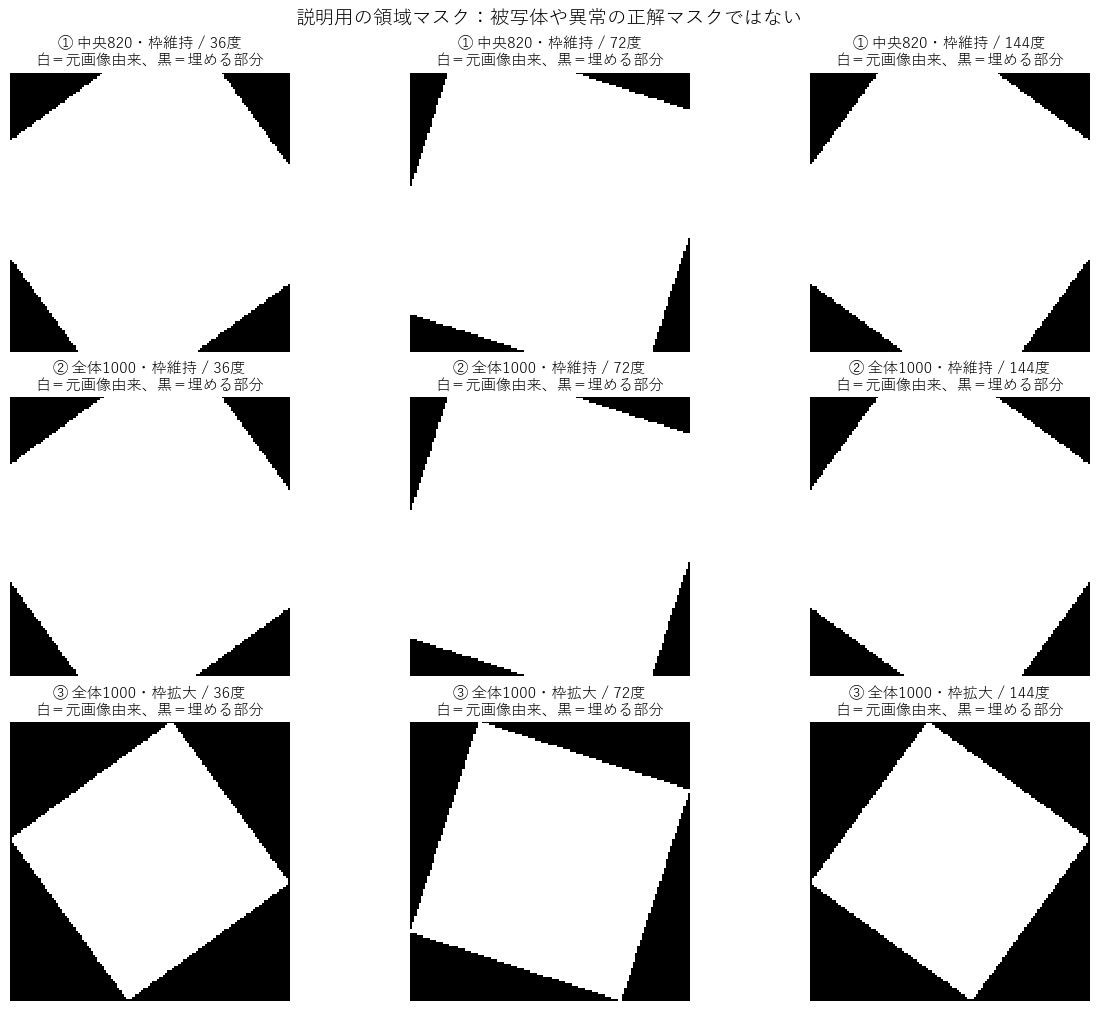

In [8]:
masks={}; rows=[]
for key,(label,im,expand) in METHODS.items():
    source_mask=Image.new('L',im.size,255)
    masks[key]={}
    for a in ANGLES:
        mask=rotate(source_mask,a,expand=expand,fill=0)
        reference=rotate(source_mask,a,expand=True,fill=0)
        valid=int(np.count_nonzero(np.asarray(mask)))
        reference_valid=int(np.count_nonzero(np.asarray(reference)))
        assert valid<=reference_valid and reference_valid>0
        masks[key][a]=mask
        rows.append({'方法':label,'角度':a,'回転後の幅':mask.width,'回転後の高さ':mask.height,
                     '白埋め率(%)':100*(1-valid/(mask.width*mask.height)),
                     '回転による切り捨て率・概算(%)':100*(1-valid/reference_valid)})
area_table=pd.DataFrame(rows)
display(area_table.round(3))
fig,axes=plt.subplots(3,len(COMPARE_ANGLES),figsize=(12,10),squeeze=False,constrained_layout=True)
for row,(key,(label,_,_)) in enumerate(METHODS.items()):
    for col,a in enumerate(COMPARE_ANGLES):
        mask=masks[key][a]
        small=mask.resize((128,128),resample=Image.Resampling.NEAREST)
        show(axes[row,col],small,f'{label} / {a}度\n白＝元画像由来、黒＝埋める部分')
fig.suptitle('説明用の領域マスク：被写体や異常の正解マスクではない',fontsize=14)
plt.show(); plt.close(fig)
assert all(np.all(np.asarray(masks[key][0])==255) for key in METHODS)
assert np.allclose(area_table.loc[area_table['方法'].str.startswith('③'),'回転による切り捨て率・概算(%)'],0)

## 7. ここまでで言えること／まだ言えないこと

| 今回確認できること | まだ確認していないこと |
|---|---|
| 横長の対象でも回転画像は作れる | 回転拡張でAUROCが改善するか |
| 切り出しだけでも対象の端を失い得る | 切り取りや白埋めが性能差の原因か |
| 枠維持では画像領域が欠け、枠拡大では縮小後の対象が小さくなる | 最適な切り出し・枠・補間の組み合わせ |
| 向きだけでなく印字の向き・画素値も変わる | 回転した向きが実際の検査で正常として許容されるか |

**「丸いかどうか」だけでは回転拡張の可否を決められません。** 回転後も検査上の正常性を保てること、対象が必要な範囲まで写っていること、実際に評価する画像と整合することが重要です。
また、bottleとcapsuleでは形状以外に色・模様・撮影条件も異なります。この比較だけで形状の影響を切り分けたことにはなりません。
将来学習比較を行う場合の前処理や比較条件は、その時点で別途決めます。

In [9]:
# 元画像が一切変更されていないことを確認し、再現に必要な設定を残す。
assert all(hashlib.sha256(p.read_bytes()).hexdigest()==source_hashes[p.name] for p in paths)
record={'date_jst':'2026-10-22','dataset':'capsule','train_normal_count':len(paths),
        'virtual_augmented_count':len(paths)*len(ANGLES),'selected_image':image_path.relative_to(ROOT).as_posix(),
        'source_sha256':source_hashes[image_path.name],'source_size':list(original.size),
        'crop_size':CROP_SIZE,'final_size':OUTPUT_SIZE,'angles':list(ANGLES),
        'compare_angles':list(COMPARE_ANGLES),'rotation_interpolation':'NEAREST','fill':255,
        'resize_interpolation':'LANCZOS','grayscale_channels':1,'input_range':[0,1],
        'pipelines':['CenterCrop820 -> Rotate expand=False -> Resize128 -> Grayscale -> ToTensor',
                     'Full image -> Rotate expand=False -> Resize128 -> Grayscale -> ToTensor',
                     'Full image -> Rotate expand=True -> Resize128 -> Grayscale -> ToTensor'],
        'source_files_unchanged':True,'repeat_pixels_identical':True,'zero_rotation_equals_repeat':True,
        'adopted_method':ADOPTED_METHOD,'adopted_crop':False,'adopted_expand':False,
        'adopted_zero_degree_equals_full_image':True,'adopted_images_count':len(adopted_inputs),
        'training_inference_auroc_executed':False,
        'versions':{name:importlib.metadata.version(name) for name in ['torch','torchvision','Pillow','numpy','matplotlib']}}
print(json.dumps(record,ensure_ascii=False,indent=2))

{
  "date_jst": "2026-10-22",
  "dataset": "capsule",
  "train_normal_count": 219,
  "virtual_augmented_count": 2190,
  "selected_image": "data/capsule/train/good/000.png",
  "source_sha256": "96a77c1cca9d6efbd4fb487c9113fe775ac0559730131850c6c6523e944611d3",
  "source_size": [
    1000,
    1000
  ],
  "crop_size": 820,
  "final_size": 128,
  "angles": [
    0,
    36,
    72,
    108,
    144,
    180,
    216,
    252,
    288,
    324
  ],
  "compare_angles": [
    36,
    72,
    144
  ],
  "rotation_interpolation": "NEAREST",
  "fill": 255,
  "resize_interpolation": "LANCZOS",
  "grayscale_channels": 1,
  "input_range": [
    0,
    1
  ],
  "pipelines": [
    "CenterCrop820 -> Rotate expand=False -> Resize128 -> Grayscale -> ToTensor",
    "Full image -> Rotate expand=False -> Resize128 -> Grayscale -> ToTensor",
    "Full image -> Rotate expand=True -> Resize128 -> Grayscale -> ToTensor"
  ],
  "source_files_unchanged": true,
  "repeat_pixels_identical": true,
  "zero_rotation_